# Lab 03 — Model selection

*Machine Learning and Data Mining — Claudio Sartori, University of Bologna*

## Goal of this lab

Put Lecture 10a into code: choose the hyperparameters of a decision tree **honestly** — with one part of the data —
and report its quality with **another** part, touched once.

| # | Step | Where |
|---|---|---|
| 1 | Lab 2's depth loop in one call: `GridSearchCV` | A — Iris |
| 2 | Why we never choose on the test set: the winner's curse, simulated and re-tested on fresh data | B — coin flips |
| 3 | Recipe 3: train / validation / test, with `ParameterGrid` | C — NordicMart |
| 4 | Recipe 4: cross-validation with `GridSearchCV`, and how to read `cv_results_` | C — NordicMart |
| 5 | Within the noise, take the simplest: the one-standard-deviation rule | C — NordicMart |
| 6 | How stable is the choice? | C — NordicMart |
| 7 | One final measure on the test set | C — NordicMart |
| ★ | Random search; confidence interval of a test accuracy; leakage inside CV | D |

- **Part A (≈ 15 min)** — Iris: the cross-validation of Lab 2, now done by scikit-learn.
- **Part B (≈ 20 min)** — a simulation with coin flips: no data set needed.
- **Part C (≈ 55 min)** — NordicMart churn: the full model-selection process on a grid of 30 configurations.
- Exercises marked ★ are optional: do them if you have time, or at home.

In this lab every model is scored with **accuracy**, as in Lab 2. On Wednesday we will see other measures, and
`GridSearchCV` will accept them with a single change.

### How to work (as in Labs 1 and 2)

- Write code in the empty cells; write **answers in markdown cells**, not in comments.
- Raw data are never modified: every change goes into a copy with a new name.
- Every random step gets a fixed `random_state`, so that your numbers are the same as the slides'.
- The **test set is the future**: you may look at it only where the text says so — at most once per part.
- Before closing: **Kernel → Restart & Run All**.

## Setup

New imports: the two search tools of Lecture 10a, `ParameterGrid` (the list of all configurations of a grid)
and two distributions from `scipy` for the optional random search.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     ParameterGrid, GridSearchCV, RandomizedSearchCV)
from sklearn.tree import DecisionTreeClassifier
from scipy.stats import randint, norm
import sklearn

DATA_DIR = Path("../../data")
NORDICMART_FILE = DATA_DIR / "nordicmart_customers.csv"
SEED = 42

pd.set_option("display.precision", 4)
plt.rcParams["figure.figsize"] = (8, 4)

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.8.0 | pandas 3.0.5


# Part A — Iris: Lab 2's loop in one call

## A1. The altered training set of Lab 2

The cell below rebuilds the data of Lab 2, Part A: the 50-50 split with `random_state=10`, and the copy of the
training set with flowers 113 and 125 altered as in Lecture 9. Run it; do not change it.

In [2]:
iris = load_iris(as_frame=True)
X = iris.data.copy()
X.columns = [c[:-5] for c in X.columns]
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.5, random_state=10)
X_train_alt, y_train_alt = X_train.copy(), y_train.copy()
y_train_alt.loc[125] = 0
X_train_alt.loc[113] = X_train_alt.loc[125]
y_train_alt.loc[113] = 1

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)   # the folds of Lab 2, step 4
print(X_train_alt.shape, y_train_alt.value_counts().sort_index().tolist())

(75, 4) [28, 24, 23]


## A2. `GridSearchCV`

In Lab 2, step 4, we wrote a loop: for each `max_depth` from 1 to 5, `cross_val_score`, then mean and standard deviation.
[`GridSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) does exactly
that loop. It is itself a model, with `fit`, `predict` and `score`; it needs three things:

- an **estimator** with the fixed hyperparameters: `DecisionTreeClassifier(criterion="entropy", random_state=10)`
- a **grid**: a dictionary `{hyperparameter name: list of values}`, here `{"max_depth": [1, 2, 3, 4, 5]}`
- the **folds**: `cv=cv`

1. Create the search object, call it `search_iris`, and `fit` it on the **altered training set** (never on the test set).
1. Print `best_params_` and `best_score_` (the best mean CV accuracy).
1. All the numbers are in the dictionary `cv_results_`. Turn it into a DataFrame and show the columns
   `param_max_depth`, `mean_test_score`, `std_test_score`, `rank_test_score`.

Careful with the names: in `cv_results_`, *test* means *the held-out fold of each round* — in Lecture 10a we called it
**validation**. The real test set never enters `GridSearchCV`.

In [3]:
search_iris = GridSearchCV(DecisionTreeClassifier(criterion="entropy", random_state=10),
                           param_grid={"max_depth": [1, 2, 3, 4, 5]}, cv=cv)
search_iris.fit(X_train_alt, y_train_alt)

print("best:", search_iris.best_params_, f"| best mean CV accuracy {search_iris.best_score_:.3f}")
pd.DataFrame(search_iris.cv_results_)[["param_max_depth", "mean_test_score", "std_test_score", "rank_test_score"]]

best: {'max_depth': 2} | best mean CV accuracy 0.960


,param_max_depth,mean_test_score,std_test_score,rank_test_score
0,1,0.68,0.0267,5
1,2,0.96,0.0327,1
2,3,0.96,0.0327,1
3,4,0.92,0.0777,3
4,5,0.92,0.0777,3


**Questions.**

1. Compare with the table of Lab 2, step 4. Same numbers?
1. Depths 2 and 3 have the same rank. Why did `GridSearchCV` choose 2? Would it always choose the simpler one?

**Answers.**

1. Identical: 0.68, 0.96, 0.96, 0.92, 0.92, with the same standard deviations. Same estimator, same folds, same data:
   `GridSearchCV` is our loop of Lab 2, nothing more.
1. In case of a tie `GridSearchCV` takes the **first** configuration in the order of the grid. We listed the depths in increasing
   order, so the first is also the simplest — by luck of the order, not by design. With `[5, 4, 3, 2, 1]` it would choose 3.
   The preference for the simpler model must be ours: section C5.

## A3. The final model is already there

With the default `refit=True`, after the search `GridSearchCV` learns the best configuration **again on all the data it was given**
(the whole altered training set, not one of the folds), and stores it in `best_estimator_`. This is step 2 of the workflow of Lecture 10a.

1. How many trees did `fit` learn in total? Compute it from the size of the grid and the number of folds.
1. Print depth and number of leaves of `best_estimator_`.
1. Now, and only now, measure it **once** on the test set: `search_iris.score(X_test, y_test)` uses `best_estimator_`.

In [4]:
n_fits = len(ParameterGrid(search_iris.param_grid)) * cv.get_n_splits() + 1
print("trees learned:", n_fits)
best_iris = search_iris.best_estimator_
print("depth:", best_iris.get_depth(), "| leaves:", best_iris.get_n_leaves())
print(f"test accuracy: {search_iris.score(X_test, y_test):.3f}")

trees learned: 26
depth: 2 | leaves: 3
test accuracy: 0.920


**Answer.** 5 configurations × 5 folds = 25 trees for the search, plus 1 for the refit: **26**. The final tree has depth 2 and 3 leaves,
and test accuracy 0.92 (6 errors out of 75): the result of Lab 2, Step 5 — Lecture 9's "open debt" is now paid with one call.

# Part B — The winner's curse, simulated

Lecture 10a, *Choosing on the test set: the winner's curse*: 20 "models" that answer at random, a test set of 50 records with two
balanced classes; we keep the model with the best test accuracy. Its true accuracy is 50%, but its test accuracy is about 63% on average.
Let us check it.

## B1. One random model

A model that flips a coin is right on each record with probability 0.5, independently: the number of correct answers on 50 records is a
**binomial** variable. `rng.binomial(n=50, p=0.5, size=...)` draws as many of them as we want.

1. Create a generator `rng = np.random.default_rng(0)`.
1. Draw the test accuracy of **one** random model on 50 records, 10 000 times (one value per repetition of the experiment).
   Print mean, minimum and maximum.

In [5]:
rng = np.random.default_rng(0)
acc_one = rng.binomial(n=50, p=0.5, size=10_000) / 50
print(f"mean {acc_one.mean():.3f} | min {acc_one.min():.2f} | max {acc_one.max():.2f}")

mean 0.500 | min 0.24 | max 0.80


## B2. Twenty random models, keep the best

Now each repetition has 20 models: draw a matrix with `size=(10_000, 20)` (one row per repetition, one column per model),
take the maximum of each row (`.max(axis=1)`), and average it. Draw the histogram of the winners' accuracies, with a vertical line
at the true accuracy 0.5.

mean accuracy of the winner: 0.631


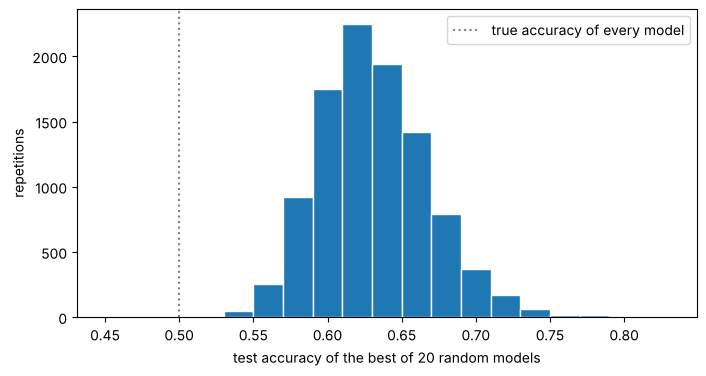

In [6]:
acc = rng.binomial(n=50, p=0.5, size=(10_000, 20)) / 50
winner = acc.max(axis=1)
print(f"mean accuracy of the winner: {winner.mean():.3f}")

fig, ax = plt.subplots()
ax.hist(winner, bins=np.arange(0.45, 0.85, 0.02), edgecolor="white")
ax.axvline(0.5, color="gray", ls=":", label="true accuracy of every model")
ax.set_xlabel("test accuracy of the best of 20 random models"); ax.set_ylabel("repetitions"); ax.legend();

## B3. More configurations, larger test sets

Write a function `winners_curse(n_test, n_models, reps=10_000)` returning the mean accuracy of the winner, and fill a table
with `n_test` in `[50, 900]` (rows) and `n_models` in `[1, 5, 20, 100]` (columns).

In [7]:
def winners_curse(n_test, n_models, reps=10_000):
    return (rng.binomial(n=n_test, p=0.5, size=(reps, n_models)) / n_test).max(axis=1).mean()

pd.DataFrame({m: [winners_curse(n, m) for n in [50, 900]] for m in [1, 5, 20, 100]},
             index=pd.Index([50, 900], name="test records")).rename_axis(columns="configurations").round(3)

configurations,1,5,20,100
test records,,,,
50,0.5,0.582,0.632,0.675
900,0.5,0.519,0.531,0.542


**Questions.**

1. How does the optimism of the winner change with the number of configurations, and with the size of the test set?
1. The NordicMart grid of Part C has 30 configurations. Why must they compete on validation data, and not on the 900 test customers?

**Answers.**

1. With one model there is no choice and no optimism (0.50). The optimism **grows with the number of configurations**
   (50 records: 0.58 with 5, 0.63 with 20, 0.68 with 100) and **shrinks with the size of the test set** (900 records: 0.52, 0.53, 0.54),
   because a larger sample fluctuates less. It never disappears.
1. Even on 900 records, the best of 30 configurations scores higher than it deserves. Real configurations are not coin flips, but their
   scores contain the same dose of luck. If the 900 customers are used to choose, the number we report is optimistic and nobody can tell by how much.
   The winner's curse must fall on data we **do not report**: validation folds. The test set stays clean for the final number.

## B4. The winner on fresh data

In B2 we knew the truth (0.50) because we built the models. In practice we do not: what reveals the curse is
**measuring the winner again on data that played no part in choosing it**.

For each of the 10 000 repetitions of B2, take the winner and score it on **50 new records**. Since every model flips
a coin, the winner too is right with probability 0.5 on each new record: draw its fresh accuracy with `rng.binomial`.

1. Print the mean accuracy of the winners on the selection set (B2) and on the fresh set.
1. Draw the two histograms on the same axes (use `alpha=0.6` to see both).

winner on the selection set: 0.631 | on fresh data: 0.500


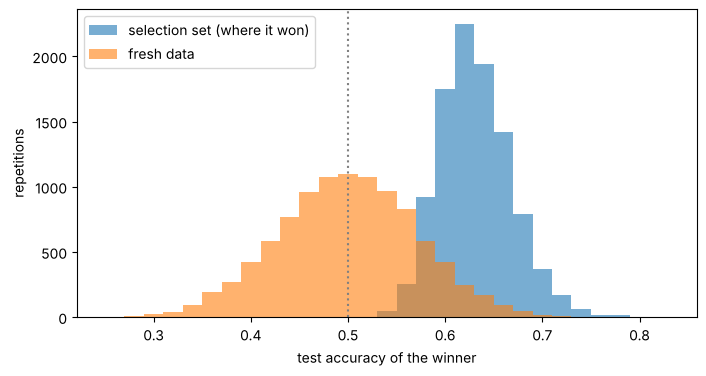

In [8]:
fresh = rng.binomial(n=50, p=0.5, size=10_000) / 50          # the same winners, 50 new records each
print(f"winner on the selection set: {winner.mean():.3f} | on fresh data: {fresh.mean():.3f}")

fig, ax = plt.subplots()
bins = np.arange(0.25, 0.85, 0.02)
ax.hist(winner, bins=bins, alpha=0.6, label="selection set (where it won)")
ax.hist(fresh, bins=bins, alpha=0.6, label="fresh data")
ax.axvline(0.5, color="gray", ls=":")
ax.set_xlabel("test accuracy of the winner"); ax.set_ylabel("repetitions"); ax.legend();

**Question.** The winner did not change between the two measures. Why did its accuracy drop?

**Answer.** From 0.63 to 0.50: the winner was chosen **because** its score on the selection set was high, and part of that score was luck.
Luck does not repeat on new records, so the fresh score falls back to the true value. This is exactly the role of a clean test set:
it is the "fresh data" that tells us how good the chosen model really is.

### The winner's curse, in one sentence

> When you pick the best of many noisy scores, the winning score is biased upwards: the winner was chosen partly for its luck,
> and luck does not repeat on new data.

The name comes from **auctions** (Capen, Clapp and Campbell, 1971, bids for offshore oil leases): each company estimates the value of
the field with some error, and the one that wins is the one that overestimated it most — so the winner tends to overpay.
Our configurations "bid" with their validation scores, and the highest bid is the most optimistic one.

Another picture: give a 10-question true/false quiz to 100 students who all answer at random. The best one scores about 9/10.
Give that student a new quiz: about 5/10.

### Skill and luck ★

Real models are not all equal. Give the 20 models true accuracies evenly spread from 0.50 to 0.60
(`np.linspace(0.50, 0.60, 20)`); on 50 records, pick the winner, then score it on 50 fresh records. Over 10 000 repetitions:
mean selection score of the winner, mean fresh score, mean **true** accuracy of the winner, and how often the winner is really the best model (0.60).

In [9]:
true_acc = np.linspace(0.50, 0.60, 20)
sel = rng.binomial(n=50, p=true_acc, size=(10_000, 20)) / 50   # each column has its own true accuracy
w = sel.argmax(axis=1)                                         # index of the winner in each repetition
fresh_w = rng.binomial(n=50, p=true_acc[w]) / 50
print(f"selection score {sel.max(axis=1).mean():.3f} | fresh score {fresh_w.mean():.3f} | "
      f"true accuracy {true_acc[w].mean():.3f} | winner is the best model in {(w == 19).mean():.1%} of the repetitions")

selection score 0.692 | fresh score 0.569 | true accuracy 0.568 | winner is the best model in 11.4% of the repetitions


**Answer.** The winner scores 0.69 where it was chosen, but only 0.57 on fresh data — which is its true accuracy (0.57): the fresh score is honest, the selection score is 12 points optimistic.
And the winner is the truly best model only 11% of the time: on 50 records, the differences in skill (at most 10 points) are drowned by the luck.
Selection on noisy scores rewards skill **and** luck; only fresh data separates them.

# Part C — NordicMart: model selection for the churn tree

## C1. Data and the locked test set

Same preparation as Lab 2, Part B:

1. Load the file into `df`.
1. Features `FEATURES = ["tier", "age", "days_since_last_buy", "annual_spend", "web_sessions_month", "tickets_90d"]`
   in a copy `Xn`, with `tier` coded Basic = 0, Silver = 1, Gold = 2; missing values stay `NaN`. Target `yn = df["churned"]`.
1. Stratified 70/30 split with `random_state=SEED`: `Xn_train, Xn_test, yn_train, yn_test`.
1. Print the sizes and the number of churners of the two parts, and the baseline accuracy ("nobody churns") on the training part.

From here to section C8 the test set is **locked**.

In [10]:
df = pd.read_csv(NORDICMART_FILE)
FEATURES = ["tier", "age", "days_since_last_buy", "annual_spend", "web_sessions_month", "tickets_90d"]
Xn = df[FEATURES].copy()
Xn["tier"] = Xn["tier"].map({"Basic": 0, "Silver": 1, "Gold": 2})
yn = df["churned"]

Xn_train, Xn_test, yn_train, yn_test = train_test_split(Xn, yn, test_size=0.3, stratify=yn, random_state=SEED)
print(f"training: {len(yn_train)} customers, {yn_train.sum()} churners | test: {len(yn_test)} customers, {yn_test.sum()} churners")
print(f"baseline accuracy on the training part: {1 - yn_train.mean():.3f}")

training: 2100 customers, 252 churners | test: 900 customers, 108 churners
baseline accuracy on the training part: 0.880


## C2. The grid

The example of Lecture 10a, *Searching the hyperparameter space*:

| hyperparameter | values |
|---|---|
| `max_depth` | 2, 3, 4, 5, 6 |
| `min_samples_leaf` | 1, 10, 30 |
| `criterion` | `"gini"`, `"entropy"` |

1. Write it as a dictionary `param_grid`.
1. `ParameterGrid(param_grid)` is the list of all the combinations, each one a dictionary. How many are there? Print the first two.

In [11]:
param_grid = {"max_depth": [2, 3, 4, 5, 6],
              "min_samples_leaf": [1, 10, 30],
              "criterion": ["gini", "entropy"]}
configs = list(ParameterGrid(param_grid))
print(len(configs), "configurations")
print(configs[:2])

30 configurations
[{'criterion': 'gini', 'max_depth': 2, 'min_samples_leaf': 1}, {'criterion': 'gini', 'max_depth': 2, 'min_samples_leaf': 10}]


A configuration dictionary can be passed to the constructor with `**`: `DecisionTreeClassifier(random_state=0, **config)`
is the same as writing `DecisionTreeClassifier(random_state=0, criterion="gini", max_depth=2, min_samples_leaf=1)`.

## C3. Recipe 3: train / validation / test

1. Split the **training part** again, stratified: 600 customers for validation, the rest for training, `random_state=SEED`.
   Call the parts `X_tr, X_val, y_tr, y_val`. How many churners are in the validation set?
1. For each of the 30 configurations: learn a tree (`random_state=0`) on `X_tr`, compute its accuracy on `X_val`.
   Collect configuration and validation accuracy in a DataFrame `val_results`, sorted from best to worst; show the top 8.

In [12]:
X_tr, X_val, y_tr, y_val = train_test_split(Xn_train, yn_train, test_size=600, stratify=yn_train, random_state=SEED)
print(f"training: {len(y_tr)} ({y_tr.sum()} churners) | validation: {len(y_val)} ({y_val.sum()} churners)")

rows = []
for config in ParameterGrid(param_grid):
    tree = DecisionTreeClassifier(random_state=0, **config).fit(X_tr, y_tr)
    rows.append({**config, "validation accuracy": tree.score(X_val, y_val)})
val_results = pd.DataFrame(rows).sort_values("validation accuracy", ascending=False, kind="stable")
val_results.head(8)

training: 1500 (180 churners) | validation: 600 (72 churners)


,criterion,max_depth,min_samples_leaf,validation accuracy
0,gini,2,1,0.8933
1,gini,2,10,0.8933
21,entropy,4,1,0.8933
22,entropy,4,10,0.8917
2,gini,2,30,0.8883
5,gini,3,30,0.8883
8,gini,4,30,0.8883
11,gini,5,30,0.8883


**Questions.**

1. Which configuration wins? By how much does it beat the second and the third?
1. If one more validation customer is classified correctly, by how many percentage points does the accuracy increase?
   Use this to express the gap between the winner and the eighth configuration as a number of customers. Is that a convincing difference?
1. Step 2 of the recipe: learn the winner again on the **whole** training part (`Xn_train`, 2100 customers). Do it, calling the model `tree_val`.
   Do not measure it on the test set yet.

In [13]:
best_val = val_results.iloc[0][["criterion", "max_depth", "min_samples_leaf"]].to_dict()
best_val["max_depth"] = int(best_val["max_depth"]); best_val["min_samples_leaf"] = int(best_val["min_samples_leaf"])
print("chosen on validation:", best_val)
print(f"one validation customer = {100 / len(y_val):.2f} points of accuracy")
tree_val = DecisionTreeClassifier(random_state=0, **best_val).fit(Xn_train, yn_train)

chosen on validation: {'criterion': 'gini', 'max_depth': 2, 'min_samples_leaf': 1}
one validation customer = 0.17 points of accuracy


**Answers.**

1. `gini`, depth 2, `min_samples_leaf=1`, with 0.8933 — **tied** with `gini`/depth 2/10 and `entropy`/depth 4/1: the first of the three in grid order wins. The fourth is one customer behind (0.8917).
1. Accuracy on 600 customers moves in steps of 1/600 = 0.17 points: every difference between two configurations is a whole number of customers.
   The eighth (0.8883) is 0.5 points, i.e. **3 customers**, behind the winner; the fourth only 1 customer. Not convincing: another random validation set could easily reverse such gaps (C6).
   The ranking rests on a handful of customers — the weak point of recipe 3 in Lecture 10a: the choice is based on a single, small portion of data.
1. Done above. Note the small trick with `int(...)`: a row of a DataFrame with mixed types stores numbers as generic objects, while scikit-learn wants integers for `max_depth`.

## C4. Recipe 4: cross-validation with `GridSearchCV`

1. Create `cv_n = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)` (the folds of Lab 2 and Lecture 10a).
1. Create `search = GridSearchCV(...)` with the estimator `DecisionTreeClassifier(random_state=0)`, the grid `param_grid`,
   `cv=cv_n` and `scoring="accuracy"`. Accuracy is the default for a classifier: we write it explicitly because on Wednesday
   this is the argument we will change.
1. `fit` it on the training part. How many trees are learned?
1. Print `best_params_` and `best_score_`.

In [14]:
cv_n = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
search = GridSearchCV(DecisionTreeClassifier(random_state=0), param_grid, cv=cv_n, scoring="accuracy")
search.fit(Xn_train, yn_train)

print("trees learned:", len(ParameterGrid(param_grid)) * cv_n.get_n_splits() + 1)
print("best:", search.best_params_, f"| mean CV accuracy {search.best_score_:.4f}")

trees learned: 151
best: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 10} | mean CV accuracy 0.8933


### Reading `cv_results_`

Build a DataFrame `res` from `search.cv_results_` with the three `param_...` columns (renamed without the prefix),
`mean_test_score`, `std_test_score` and `rank_test_score`, sorted by rank. Show the top 10.
Also look at the columns `split0_test_score` … `split4_test_score`: what are they?

In [15]:
res = (pd.DataFrame(search.cv_results_)
         .rename(columns=lambda c: c.replace("param_", ""))
         [["criterion", "max_depth", "min_samples_leaf", "mean_test_score", "std_test_score", "rank_test_score"]]
         .sort_values(["rank_test_score", "max_depth"], kind="stable"))
res.head(10)

,criterion,max_depth,min_samples_leaf,mean_test_score,std_test_score,rank_test_score
25,entropy,5,10,0.8933,0.0114,1
28,entropy,6,10,0.8929,0.0112,2
6,gini,4,1,0.8905,0.0062,3
20,entropy,3,30,0.8890,0.0086,4
23,entropy,4,30,0.8890,0.0086,4
26,entropy,5,30,0.8890,0.0086,4
29,entropy,6,30,0.8890,0.0086,4
15,entropy,2,1,0.8886,0.0093,8
16,entropy,2,10,0.8886,0.0093,8
17,entropy,2,30,0.8886,0.0093,8


**Answer.** The winner is `entropy`, depth 5, `min_samples_leaf=10`, with 0.8933 ± 0.0114; the second is 0.0004 behind, the tenth 0.0047 behind (less than half a standard deviation). Note the ties: identical scores usually mean *identical trees* — e.g. at depth 2 every leaf holds far more than 30 customers, so `min_samples_leaf` 1, 10 and 30 build the same tree. The columns `split0_test_score` … `split4_test_score` are the accuracies of the 5 rounds, one per held-out fold:
`mean_test_score` and `std_test_score` are their mean and standard deviation — the five numbers of Lab 2, step 2, for every configuration.

### The whole grid in one picture

Plot the mean CV accuracy against `max_depth`, one line for each combination of `criterion` and `min_samples_leaf` (6 lines),
with **error bars of ± one standard deviation** (`ax.errorbar(..., yerr=...)`, as in Lab 2, B4) and the baseline as a horizontal dotted line.
Hints: loop over `res.groupby(["criterion", "min_samples_leaf"])` and sort each group by `max_depth` before plotting;
with six lines the bars overlap, so shift each line slightly to the left or right (e.g. `max_depth + offset`, with offsets
between −0.2 and +0.2).

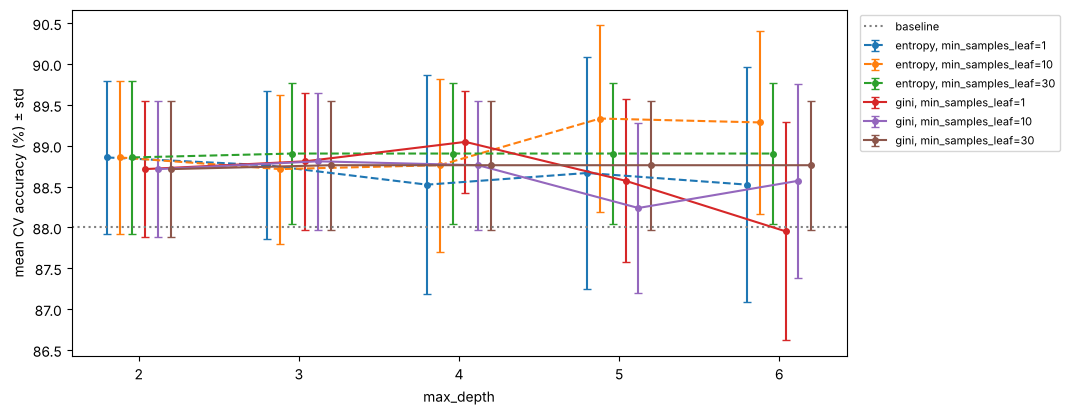

In [16]:
fig, ax = plt.subplots(figsize=(10, 4.5))
groups = res.groupby(["criterion", "min_samples_leaf"])
offsets = np.linspace(-0.2, 0.2, groups.ngroups)              # one small horizontal shift per line
for off, ((crit, msl), g) in zip(offsets, groups):
    g = g.sort_values("max_depth")
    ax.errorbar(g["max_depth"] + off, g["mean_test_score"] * 100, yerr=g["std_test_score"] * 100,
                marker="o", ms=4, capsize=3, ls="-" if crit == "gini" else "--",
                label=f"{crit}, min_samples_leaf={msl}")
ax.axhline((1 - yn_train.mean()) * 100, color="gray", ls=":", label="baseline")
ax.set_xticks(param_grid["max_depth"])
ax.set_xlabel("max_depth"); ax.set_ylabel("mean CV accuracy (%) ± std")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1));     # legend outside, not over the bars

**Question.** Compare the spread of the 30 mean accuracies with the standard deviation of the best configuration.
Is the winner of `GridSearchCV` clearly better than the others?

**Answer.** All 30 means lie between 87.95% and 89.33%: a spread of 1.4 points, about the size of the best configuration's standard deviation (1.1 points), with no clear pattern among the lines. The error bars show it directly: almost every bar overlaps the winner's. The baseline (88.0%) sits at the bottom of the band. The winner of `GridSearchCV` is the top of a flat plateau, not a clearly better model: rerun with other folds and the ranking may change (C6).

## C5. Within the noise, take the simplest

Lecture 10a, *Reading the cross-validation results*: among the configurations whose mean is within **one standard deviation** of the best,
take the **simplest**. For a tree, simpler means: smaller `max_depth` first; for the same depth, larger `min_samples_leaf`
(more customers per leaf, fewer leaves).

This is a **heuristic**, not a statistical test. The standard deviation of the 5 fold scores is not a confidence interval:
the rounds share most of their training data, so they are not independent, and 5 values give only a rough estimate.
We use it as a scale for the noise when comparing configurations scored on the same folds — the same scale as the error bars of C4.
(Hastie, Tibshirani and Friedman's *one-standard-error rule* uses std/√k instead, about 2.2 times narrower for k = 5: our version is more conservative.)

1. Compute the threshold: mean of the best configuration minus its standard deviation.
1. Select the candidates of `res` at or above the threshold. How many are there?
1. Sort the candidates by `max_depth` (increasing), then `min_samples_leaf` (decreasing), then `mean_test_score` (decreasing),
   and take the first one: call its hyperparameters `chosen` (a dictionary, with integer values for the two numbers).

In [17]:
best = res.iloc[0]
threshold = best["mean_test_score"] - best["std_test_score"]
candidates = res[res["mean_test_score"] >= threshold]
print(f"threshold {threshold:.4f} -> {len(candidates)} candidates out of {len(res)}")

simplest = candidates.sort_values(["max_depth", "min_samples_leaf", "mean_test_score"],
                                  ascending=[True, False, False], kind="stable").iloc[0]
chosen = {"criterion": simplest["criterion"], "max_depth": int(simplest["max_depth"]),
          "min_samples_leaf": int(simplest["min_samples_leaf"])}
print("chosen:", chosen, f"| mean CV accuracy {simplest['mean_test_score']:.4f} ± {simplest['std_test_score']:.4f}")

threshold 0.8819 -> 29 candidates out of 30
chosen: {'criterion': 'entropy', 'max_depth': 2, 'min_samples_leaf': 30} | mean CV accuracy 0.8886 ± 0.0093


**Answer.** Threshold 0.8933 − 0.0114 = 0.8819: **29 of the 30 configurations** are candidates — all but `gini`/depth 6/1. The simplest is `entropy`, depth 2, `min_samples_leaf=30`, with 0.8886 ± 0.0093: 0.5 points below the winner, less than half a standard deviation, with a tree of 4 leaves instead of a depth-5 tree. With the narrower standard error (0.0114/√5 = 0.0051) the threshold would be 0.8882: the chosen tree (0.8886) would still pass, so here the choice does not change.

## C6. How stable is the choice?

The validation set of C3 and the folds of C4 are random. Change the randomness and look at the winner.

1. Repeat recipe 3 (C3) with 5 different validation splits: `random_state` from 0 to 4 in the second `train_test_split`.
   For each, print the winning configuration and its validation accuracy.
1. Repeat recipe 4 (C4) with 5 different fold partitions: `StratifiedKFold(5, shuffle=True, random_state=r)`, `r` from 0 to 4.
   For each, print `best_params_` and `best_score_`.

Write a small helper `show(config)` that prints a configuration compactly, e.g. `gini/d2/msl30`.

In [18]:
def show(c):
    return f"{c['criterion']}/d{int(c['max_depth'])}/msl{int(c['min_samples_leaf'])}"

print("recipe 3, five validation splits")
for r in range(5):
    Xa, Xb, ya, yb = train_test_split(Xn_train, yn_train, test_size=600, stratify=yn_train, random_state=r)
    scores = [(DecisionTreeClassifier(random_state=0, **c).fit(Xa, ya).score(Xb, yb), c) for c in ParameterGrid(param_grid)]
    acc_best, c_best = max(scores, key=lambda t: t[0])           # first maximum, in grid order
    print(f"  split {r}: {show(c_best):18s} validation accuracy {acc_best:.4f}")

print("recipe 4, five fold partitions")
for r in range(5):
    s = GridSearchCV(DecisionTreeClassifier(random_state=0), param_grid,
                     cv=StratifiedKFold(5, shuffle=True, random_state=r), scoring="accuracy").fit(Xn_train, yn_train)
    print(f"  folds {r}: {show(s.best_params_):18s} mean CV accuracy {s.best_score_:.4f}")

recipe 3, five validation splits


  split 0: gini/d2/msl1       validation accuracy 0.9000


  split 1: entropy/d3/msl30   validation accuracy 0.8850


  split 2: gini/d2/msl1       validation accuracy 0.8950


  split 3: gini/d5/msl1       validation accuracy 0.8950


...

  folds 0: entropy/d5/msl10   mean CV accuracy 0.8933


  folds 1: gini/d2/msl1       mean CV accuracy 0.8910


  folds 2: gini/d3/msl30      mean CV accuracy 0.8910


  folds 3: gini/d2/msl1       mean CV accuracy 0.8929


  folds 4: gini/d2/msl1       mean CV accuracy 0.8948


**Questions.**

1. Does the winner change? With which recipe is the *score* of the winner more stable?
1. What does this tell you about the meaning of "the best configuration" here?

**Answers.**

1. Yes, with both recipes. Recipe 3 gives **four different winners** in five splits (`gini`/d2/1 twice, `entropy`/d3/30, `gini`/d5/1, `gini`/d4/10), with validation scores from 0.885 to 0.900: 1.5 points of range, from 600 customers. Recipe 4 gives **three winners** (`gini`/d2/1 three times, `entropy`/d5/10, `gini`/d3/30), with scores from 0.891 to 0.895: 0.4 points. Cross-validation averages over all 2100 customers, so its score is much more stable — the advantage of recipe 4 in Lecture 10a.
1. There is no single "best configuration" here: a plateau of configurations is equivalent **as far as accuracy can tell**, and the winner is decided by the noise. A rule that does not depend on the noise (the simplest within one standard deviation) is more reproducible. And perhaps a different measure can separate them: Wednesday.

## C7. Before opening the test set: write down the decision

The final model must be decided **before** looking at the test set. Our procedure, fixed in advance:
*grid search with 5-fold CV on the training part, then the simplest configuration within one standard deviation of the best* — that is `chosen` of C5.

`search.best_estimator_` is already refitted on the 2100 training customers, but with the configuration of rank 1, not `chosen`.
Learn `final = DecisionTreeClassifier(random_state=0, **chosen)` on the whole training part.

In [19]:
final = DecisionTreeClassifier(random_state=0, **chosen).fit(Xn_train, yn_train)
print(show(chosen), "| depth", final.get_depth(), "| leaves", final.get_n_leaves())

entropy/d2/msl30 | depth 2 | leaves 4


## C8. One look at the test set

Now, **once**:

1. Test accuracy of `final`, its CV estimate from C5, and the baseline accuracy on the test set ("nobody churns").
1. The cross-table of actual vs predicted classes on the test set (`pd.crosstab`, as in Lab 2).

In [20]:
pred = pd.Series(final.predict(Xn_test), index=yn_test.index, name="predicted")
print(f"test accuracy {final.score(Xn_test, yn_test):.4f} | CV estimate {simplest['mean_test_score']:.4f}"
      f" | baseline on test {1 - yn_test.mean():.4f}")
pd.crosstab(yn_test.rename("actual"), pred)

test accuracy 0.8889 | CV estimate 0.8886 | baseline on test 0.8800


predicted,0,1
actual,,
0,778,14
1,86,22


**Questions.**

1. Is the test accuracy consistent with the CV estimate? Is the tree better than "nobody churns"?
1. Read the cross-table: how many of the 108 test churners does the tree recognize? How many customers does it wrongly flag as churners?
1. NordicMart wants to contact the customers at risk of leaving. Is accuracy the right number to choose the tree with?

**Answers.**

1. Test accuracy 88.9%, CV estimate 88.9%: consistent (the identical decimals are luck: on 900 customers a test accuracy is uncertain by about ±2 points, Section 5 of Lecture 10a). The baseline on the test set is 88.0%: the tree is better by 0.9 points, i.e. **8 customers out of 900**.
1. The tree recognizes **22 of the 108 churners** (20%) and misses 86; it wrongly flags **14** loyal customers as churners.
1. No. Accuracy counts all errors alike, and is dominated by the 792 loyal customers: a tree that finds no churner at all still scores 88%. For a retention campaign what matters is *how many churners we find* and *how many contacts we waste* — two numbers that can be read in the cross-table but not in the accuracy. Choosing the tree with those numbers is the subject of Wednesday's lecture: then `scoring="accuracy"` in C4 will be replaced, and the winner will change.

# Part D — Optional exercises ★

## D1. Random search ★

Lecture 10a: with the same budget, random search explores **more distinct values** of each hyperparameter.
Use [`RandomizedSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html)
with the same budget as the grid (`n_iter=30`), the same folds `cv_n`, `random_state=0`, and the distributions

- `max_depth`: `randint(2, 13)` (integers from 2 to 12)
- `min_samples_leaf`: `randint(1, 101)` (integers from 1 to 100)
- `criterion`: `["gini", "entropy"]` (a list: chosen uniformly)

How many distinct values of `max_depth` and of `min_samples_leaf` did it try? Compare the best mean CV accuracy with the grid's.

In [21]:
rsearch = RandomizedSearchCV(DecisionTreeClassifier(random_state=0),
                             {"max_depth": randint(2, 13), "min_samples_leaf": randint(1, 101),
                              "criterion": ["gini", "entropy"]},
                             n_iter=30, cv=cv_n, scoring="accuracy", random_state=0)
rsearch.fit(Xn_train, yn_train)
rres = pd.DataFrame(rsearch.cv_results_)
print("distinct max_depth:", rres["param_max_depth"].nunique(), "| distinct min_samples_leaf:", rres["param_min_samples_leaf"].nunique())
print("random search best:", rsearch.best_params_, f"{rsearch.best_score_:.4f}")
print("grid search best:  ", search.best_params_, f"{search.best_score_:.4f}")

distinct max_depth: 10 | distinct min_samples_leaf: 28
random search best: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 10} 0.8933
grid search best:   {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 10} 0.8933


**Answer.** Random search tried 10 distinct depths and 28 distinct values of `min_samples_leaf` (the grid: 5 and 3), with the same budget of 30 configurations. Its best is the same as the grid's (`entropy`/d5/10, 0.8933: one random draw hit it), and several configurations with very different depths but a large `min_samples_leaf` tie at 0.8886 — a large minimum leaf stops the tree early, whatever `max_depth` says. On this flat landscape neither search can do better: the limit is the data and the measure, not the search.

## D2. How precise is a test accuracy? ★

*(Only if Section 5 of Lecture 10a, the Wilson score interval, was covered in class.)*

Write a function `wilson(errors, n, conf=0.95)` returning the interval for the true error probability $p$:

$$
p \in \frac{1}{1+\frac{z^{2}}{n}}\left[ f + \frac{z^{2}}{2n} \pm z\sqrt{\frac{f(1-f)}{n}+\frac{z^{2}}{4n^{2}}} \right],
\qquad f = \frac{\text{errors}}{n},\quad z = \texttt{norm.ppf}(1 - \alpha/2)
$$

1. Check it on the slide *Worked examples (95%)*: Iris depth 2, 6 errors out of 75 → [3.7%, 16.4%].
1. Apply it to `final` and to the baseline on the 900 test customers. Do the two intervals overlap?

In [22]:
def wilson(errors, n, conf=0.95):
    z = norm.ppf(1 - (1 - conf) / 2)
    f = errors / n
    centre = f + z**2 / (2 * n)
    half = z * np.sqrt(f * (1 - f) / n + z**2 / (4 * n**2))
    return (centre - half) / (1 + z**2 / n), (centre + half) / (1 + z**2 / n)

lo, hi = wilson(6, 75)
print(f"Iris depth 2, 6/75:   [{lo:.1%}, {hi:.1%}]")
e_final = int((final.predict(Xn_test) != yn_test).sum())
e_base = int(yn_test.sum())                                   # "nobody churns" misses every churner
for name, e in [("final tree", e_final), ("baseline", e_base)]:
    lo, hi = wilson(e, len(yn_test))
    print(f"{name:12s} {e:3d}/{len(yn_test)} = {e / len(yn_test):.1%}  ->  [{lo:.1%}, {hi:.1%}]")

Iris depth 2, 6/75:   [3.7%, 16.4%]
final tree   100/900 = 11.1%  ->  [9.2%, 13.3%]
baseline     108/900 = 12.0%  ->  [10.0%, 14.3%]


**Answer.** The function reproduces the slide: [3.7%, 16.4%]. The final tree makes 100 errors out of 900 (11.1%, interval [9.2%, 13.3%]); the baseline 108 (12.0%, interval [10.0%, 14.3%]). The intervals **overlap almost completely**: on accuracy, there is no evidence that the tree is better than "nobody churns". Report estimate and uncertainty, never the estimate alone.

## D3. Leakage inside cross-validation ★

Lecture 10a, *Leakage inside cross-validation*: a preparation step that **computes** something from the data must be recomputed
inside each round, on the training folds only. The effect can be dramatic. An extreme case, with pure noise:

- 100 individuals, 5000 random features, a random binary target: **nothing** can be predicted, the true accuracy is 50%.
- Preparation step: keep the 10 features whose mean differs most between the two classes.

The cell below creates the data and the selection function (run it, do not change it).

In [23]:
rng_noise = np.random.default_rng(1)
Xz = pd.DataFrame(rng_noise.normal(size=(100, 5000)))
yz = pd.Series(np.repeat([0, 1], 50))

def top_features(X, y, k=10):
    # the k columns with the largest difference between the class means, computed on (X, y)
    diff = (X[y == 1].mean() - X[y == 0].mean()).abs()
    return diff.nlargest(k).index

cv_z = StratifiedKFold(5, shuffle=True, random_state=0)

1. **Wrong**: select the 10 features on **all** of `Xz`, then `cross_val_score` of a `DecisionTreeClassifier(max_depth=2, random_state=0)`
   on those 10 columns.
1. **Right**: loop over the rounds of `cv_z.split(Xz, yz)`; in each round select the 10 features on the **training folds only**,
   learn the tree on them, and score it on the held-out fold.

In [24]:
cols = top_features(Xz, yz)
wrong = cross_val_score(DecisionTreeClassifier(max_depth=2, random_state=0), Xz[cols], yz, cv=cv_z)

right = []
for learn_pos, held_pos in cv_z.split(Xz, yz):
    X_learn, y_learn = Xz.iloc[learn_pos], yz.iloc[learn_pos]
    cols_r = top_features(X_learn, y_learn)                      # chosen without the held-out fold
    tree = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X_learn[cols_r], y_learn)
    right.append(tree.score(Xz.iloc[held_pos][cols_r], yz.iloc[held_pos]))
right = np.array(right)

print(f"wrong (selection before CV): {wrong.mean():.2f} ± {wrong.std():.2f}")
print(f"right (selection inside CV): {right.mean():.2f} ± {right.std():.2f}")

wrong (selection before CV): 0.69 ± 0.09
right (selection inside CV): 0.48 ± 0.07


**Answer.** Wrong: 0.69 ± 0.09 — a model that seems to predict pure noise. Right: 0.48 ± 0.07 — the truth, chance level.
With 5000 random features, some differ between the two classes **by chance**; choosing them on all the data, the held-out folds have
already voted for "their" features, so they are no longer a future the model has not seen. The leakage is in the selection, not in the tree:
`cross_val_score` cannot see it because the selection happened before it was called. The rule: every step that computes something from the data goes
**inside** each round. Doing it by hand is tedious: scikit-learn *pipelines* automate it, and will come with data preparation (session 16).

## Experiment log

Complete the log (double-click to edit). The test column is filled only for the final models, once.

| Data | Model | How chosen | CV accuracy | Test accuracy |
|---|---|---|---|---|
| Iris, altered | tree, `max_depth=2` | `GridSearchCV`, 5-fold (tie broken by grid order) | 0.96 ± 0.03 | 92% (6 errors) |
| NordicMart | majority class | — | — | 88.0% |
| NordicMart | `gini`, depth 2, leaf ≥ 1 | recipe 3: one validation set of 600 | (validation 0.893) | not measured |
| NordicMart | `entropy`, depth 5, leaf ≥ 10 | recipe 4: `GridSearchCV`, rank 1 | 0.893 ± 0.011 | not measured |
| NordicMart | `entropy`, depth 2, leaf ≥ 30 | recipe 4 + simplest within one std | 0.889 ± 0.009 | 88.9% (22 of 108 churners found) |

## Before you close

1. **Kernel → Restart & Run All**: the notebook must run from top to bottom without errors.
1. Check that the test sets were used only in A3 (Iris), C8 and D2 (NordicMart).

In [25]:
# quick self-check
assert len(Xn_test) == 900 and yn_test.sum() == 108
assert search.n_splits_ == 5 and len(search.cv_results_["params"]) == 30
assert search_iris.best_params_ == {"max_depth": 2}
print("ok")

ok
